In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [4]:
df_raw = pd.read_csv("data/water-quality.csv")
df_raw.to_csv("data/self_raw/raw_data.csv", index=False)
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7996 entries, 0 to 7995
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   aluminium    7996 non-null   float64
 1   ammonia      7996 non-null   float64
 2   arsenic      7996 non-null   float64
 3   barium       7996 non-null   float64
 4   cadmium      7996 non-null   float64
 5   chloramine   7996 non-null   float64
 6   chromium     7996 non-null   float64
 7   copper       7996 non-null   float64
 8   flouride     7996 non-null   float64
 9   bacteria     7996 non-null   float64
 10  viruses      7996 non-null   float64
 11  lead         7996 non-null   float64
 12  nitrates     7996 non-null   float64
 13  nitrites     7996 non-null   float64
 14  mercury      7996 non-null   float64
 15  perchlorate  7996 non-null   float64
 16  radium       7996 non-null   float64
 17  selenium     7996 non-null   float64
 18  silver       7996 non-null   float64
 19  uranium      7996

In [5]:
df_raw.head()

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1


Wasserqualität zeigt keinerlei fehlende Werte, Daten sind komplett 👍

Datentyp von Spalte "is_safe" wird jedoch von int auf bool umgestellt:

In [37]:
#Umwandeln  von is_safe von int auf bool
df = df_raw.copy()
df["is_safe"] = df["is_safe"].astype(bool)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7996 entries, 0 to 7995
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   aluminium    7996 non-null   float64
 1   ammonia      7996 non-null   float64
 2   arsenic      7996 non-null   float64
 3   barium       7996 non-null   float64
 4   cadmium      7996 non-null   float64
 5   chloramine   7996 non-null   float64
 6   chromium     7996 non-null   float64
 7   copper       7996 non-null   float64
 8   flouride     7996 non-null   float64
 9   bacteria     7996 non-null   float64
 10  viruses      7996 non-null   float64
 11  lead         7996 non-null   float64
 12  nitrates     7996 non-null   float64
 13  nitrites     7996 non-null   float64
 14  mercury      7996 non-null   float64
 15  perchlorate  7996 non-null   float64
 16  radium       7996 non-null   float64
 17  selenium     7996 non-null   float64
 18  silver       7996 non-null   float64
 19  uranium      7996

In [38]:
#Speichern von der 'bereinigten' Datei in 'data/self_cleaned/'
df.to_csv("data/self_cleaned/cleaned_data.csv", index=False)

**Target Column:**
Target-Column = 'is_safe'

**Problem:**
→ Klassifizierungsproblem (sicher vs. unsicher)

---
Beispiel Regression: Vorhersage eines Hauspreises, wie im King-County-Projekt
- Eingaben: Wohnfläche, Anzahl der Zimmer, Baujahr und Lage.
- Zielwert: Verkaufspreis.
- Vorhersage: beispielsweise 425.000 €.

→ Regression, weil das Modell einen Zahlenwert vorhersagt.

> Jetzt werden aus den Daten zwei DataFrames erstellt:
> - Eine Liste ohne Ergebnisse
> - Eine Liste mit nur den entsprechenden Ergebnissen

Das ist notwendig um das Modell zu trainieren.

In [8]:
X = df.drop(columns="is_safe")
y = df["is_safe"]

In [9]:
y.value_counts(dropna=False)

is_safe
False    7084
True      912
Name: count, dtype: int64

Man sieht mit y.value_counts die  Klassenverteilung von 'is_safe':
- ca. 89 % sind FALSE
- ca. 11 % sind TRUE

Dieses Verhältnis soll in Trainings- und Testdaten ähnlich bleiben, damit:
- Das Modell beim Lernen beide Klassen im ursprünglichen Verhältnis sieht.
- Der Test den vorhandenen Datensatz möglichst gut widerspiegelt. Enthielte er zufällig fast nur unsichere Proben, könnten wir kaum beurteilen, wie gut das Modell sichere Proben erkennt.

Ein extremes Beispiel: Im Test wären ausschließlich unsichere Proben.  \
Ein Modell, das immer „unsicher“ vorhersagt, hätte dann 100 % Accuracy, obwohl es keine sichere Probe erkennt.  \
```stratify=y``` verhindert solche zufälligen Verschiebungen bei der Aufteilung weitgehend.  \
Das bestehende Klassenungleichgewicht behebt es allerdings nicht.

Aufteilen der Daten in Trainings- und Testdaten:

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Prüfen, ob die Klassenverteilung von 'is_safe' aus den  Grunddaten erhalten geblieben ist ('stratify = y' hilft hierbei):

In [11]:
y_train.value_counts(normalize=True)

is_safe
False    0.885866
True     0.114134
Name: proportion, dtype: float64

In [12]:
y_test.value_counts(normalize=True)

is_safe
False    0.88625
True     0.11375
Name: proportion, dtype: float64

Klassenverteilung ist erhalten geblieben 👍

Jetzt folgt die Pipeline aus Skalierung und Modell - sie verbindet zwei Schritte.

1. StandardScaler bringt die Messwerte auf vergleichbare Größenordnungen. Dafür lernt er beim Training den Mittelwert und die Standardabweichung jeder Eingabespalte. 

> - Die Daten haben unterschiedliche Werte von 0,0001 bis 100.000 usw. Eine größere Zahl bedeutet jedoch nicht automatisch, dass dieses Merkmal wichtiger ist.
> - Ohne Skalierung kann das Modell trotzdem funktionieren, aber Training und Ergebnis können ungünstiger ausfallen. Bei anderen Modellen, etwa Entscheidungsbäumen, ist diese Skalierung normalerweise nicht nötig.

2. LogisticRegression lernt anschließend aus den skalierten Messwerten, zwischen False und True zu unterscheiden.
Die Pipeline sorgt dafür, dass später auch Testdaten mit denselben beim Training gelernten Werten skaliert werden.

> - Das ist das eigentliche Modell, das den Zusammenhang zwischen Messwerten und is_safe lernt. Der Scaler allein kann keine Wasserprobe klassifizieren.
Für diese Aufgabe benötigt man ein Klassifikationsmodell.  \
Logistic Regression ist dafür ein einfacher Ausgangspunkt; andere Klassifikationsmodelle wären ebenfalls möglich.

In [13]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression()),
])

**.fit()** bedeutet aus Daten lernen → die Pipeline trainieren 💪

1. Der StandardScaler lernt Mittelwert und Standardabweichung jeder Spalte aus X_train. Damit skaliert er die Trainingsdaten.

2. Die LogisticRegression lernt aus diesen skalierten Messwerten und den bekannten Antworten in y_train, welche Zusammenhänge auf sichere oder unsichere Wasserproben hinweisen. Dabei passt sie ihre Modellkoeffizienten an.

Die gelernten Werte werden in deiner Pipeline gespeichert.

---
- .fit() = Lernen mit Beispielen und bekannten Antworten
- .predict() = Das Gelernte auf weitere Beispiele anwenden

In [14]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['aluminium','ammonia','arsenic',...,'selenium','silver','uranium']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [15]:
X_train.head()

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,viruses,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium
5068,0.06,10.11,0.04,0.50,0.00,0.00,0.05,1.55,1.09,0.00,0.720,0.137,14.66,0.64,0.001,0.02,1.52,0.09,0.06,0.03
5776,0.04,24.02,0.05,0.85,0.03,0.12,0.06,0.20,0.28,0.46,0.006,0.113,11.97,0.71,0.005,2.28,0.61,0.10,0.01,0.07
5493,0.02,23.60,0.04,1.61,0.00,0.07,0.06,1.27,0.21,0.00,0.670,0.092,5.81,0.71,0.010,5.04,0.32,0.08,0.05,0.09
4590,0.02,2.79,0.01,0.50,0.07,0.07,0.02,0.03,0.74,0.00,0.950,0.124,15.45,0.50,0.000,3.81,0.54,0.08,0.05,0.07
7241,0.05,3.86,0.00,0.13,0.01,0.63,0.07,1.99,1.44,0.15,0.003,0.100,4.54,2.66,0.010,3.93,0.99,0.02,0.02,0.04


In [16]:
y_train.head()

5068    False
5776    False
5493    False
4590    False
7241    False
Name: is_safe, dtype: bool

Nach .fit() steckt das Gelernte im Objekt pipeline – zunächst nur im Arbeitsspeicher deines laufenden Notebook-Kernels.
Es wird dabei nicht automatisch eine Datei gespeichert.

Die Pipeline enthält jetzt:
| Bestandteil | Was wurde beim Training gespeichert? |
|---|---|
| `StandardScaler` | Mittelwert und Standardabweichung jeder Eingabespalte |
| `LogisticRegression` | Gelernte Gewichte (**Koeffizienten**) und ein Basiswert (**Intercept**), aus denen das Modell seine Vorhersagen berechnet |


Die erkannten „Muster“ stecken also in gelernten Zahlenwerten, Beispielsweise im Modellkoeffizienten:
```pipeline.named_steps["model"].coef_```


Bei anschließenden  aufruf von ```pipeline.predict(X_test)``` greift die Pipeline auf diese gespeicherten Werte zurück.  \
→ Sie muss dafür nicht erneut lernen.


> **Wichtig für später:** Ein Neustart des Kernels löscht diesen Zustand aus dem Arbeitsspeicher.  \
Das Speichern der .ipynb-Datei bewahrt zwar Code und angezeigte Ausgaben, aber nicht automatisch das trainierte Modellobjekt.  \
Um es später ohne erneutes Training zu verwenden, speichern wir die gesamte trainierte Pipeline als Modelldatei.  \
Dadurch bleiben sowohl die Skalierungswerte als auch das gelernte Modell erhalten.

In [17]:
pipeline.named_steps["model"].coef_

array([[ 0.90675356, -0.23099185, -0.83847006,  0.14098323, -0.77845857,
         0.46048207,  0.36471457, -0.21600778,  0.07100541,  0.24125734,
        -0.4797205 , -0.07849181, -0.29428898, -0.18319813, -0.13034006,
        -0.45886486, -0.17197809, -0.1585026 , -0.19415539, -0.38135741]])

**.predict()** erstellt Vorhersagen für einen Datensatz, hier 'X_test'

Die Antworten dazu stehen in  'y_test' und dienen zur Bewertung des Models.

In [26]:
y_pred = pipeline.predict(X_test)

Nun kommt die Bewertung über classification_report:

- y_test: tatsächliche Klassen
- y_pred: vorhergesagte Klassen

Der Bericht zeigt für False und True jeweils Precision, Recall und F1-Score.

Support gibt an, wie viele Testproben tatsächlich zur jeweiligen Klasse gehören.

In [27]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.92      0.98      0.95      1418
        True       0.71      0.33      0.45       182

    accuracy                           0.91      1600
   macro avg       0.82      0.66      0.70      1600
weighted avg       0.90      0.91      0.89      1600



| Kennzahl | Wert | Bedeutung |
|---|---:|---|
| **support** | 182 | Im Test sind tatsächlich 182 sichere Proben. |
| **Recall** | 0,33 | Von diesen sicheren Proben erkennt das Modell nur etwa **33 %** – ungefähr 60 Stück. |
| **Precision** | 0,71 | Von den Proben, die das Modell als sicher einstuft, sind etwa **71 % tatsächlich sicher**. |
| **F1-Score** | 0,45 | Fasst Precision und Recall zu einer gemeinsamen Kennzahl zusammen. |

Als Nächstes machen wir die Fehler als konkrete Anzahlen sichtbar.

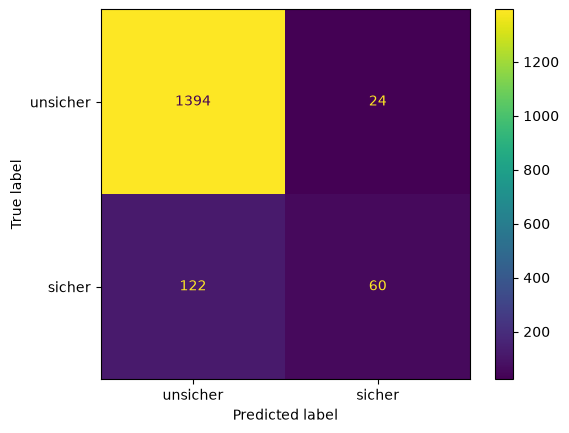

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["unsicher","sicher"]
)

plt.show()

Links steht die tatsächliche Klasse, unten die Vorhersage des Modells.
| Tatsächlich ↓ / Vorhergesagt → | Unsicher | Sicher |
|---|---:|---:|
| **Unsicher** | **1.394 richtig** als unsicher erkannt | **24 falsch** als sicher eingestuft |
| **Sicher** | **122 falsch** als unsicher eingestuft | **60 richtig** als sicher erkannt |

Die Diagonale von links oben nach rechts unten enthält die richtigen Vorhersagen

Die anderen beiden Felder enthalten die Fehler.

- Precision: Das Modell sagt bei 24 + 60 = 84 Proben „sicher“. Davon stimmen 60
- Recall: Tatsächlich sicher sind 122 + 60 = 182 Proben. Davon stimmen 60

Damit erkennt man genau, wie viele Proben richtig oder falsch zugeordnet wurden.

Das Grundmodell steht nun.

Jetzt folgt das Hyperparameter-Tuning → Wir prüfen, ob andere Modelleinstellungen bessere Ergebnisse liefern.

Zunächst halten wir den bisherigen F1-Score als Vergleichswert fest.

In [21]:
baseline_f1 = f1_score(y_test, y_pred)
print(f"Baseline F1: {baseline_f1:.3f}")

Baseline F1: 0.451


Als erste Einstellung untersuchen wir **C** bei Logistic Regression.

Dieser Hyperparameter steuert die Stärke der Regularisierung, also wie stark große Modellkoeffizienten begrenzt werden:
- kleines **C**: stärkere Begrenzung
- großes **C**: schwächere Begrenzung

Dazu erstellen wir ein  Dictionary:

In [23]:
param_distributions_C = {
    "model__C":[0.01, 0.1, 1, 10, 100]
}

```model__C``` bedeutet: Parameter **C** des Pipeline-Schritts "model".  \
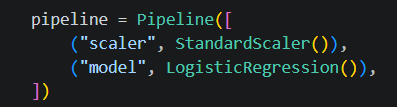  \
Die beiden Unterstriche verbinden Schrittname und Parametername.

Um den besten Wert zu finden benutzen wir akribische Suche mittels ```RanomizedSearchCV``` mit folgenden Parametern:
- **estimator** = pipeline: Untersucht wird die gesamte Pipeline inklusive Skalierung
- **param_distributions**: Hier stehen die möglichen Werte für ```model__C``` aus ```param_distributions_C```
- **n_iter=5**: Fünf Einstellungen ausprobieren – bei deiner Liste werden damit alle fünf Werte getestet
- **scoring="f1"**: Scoring wird durch ```F1``` bestimmt. ```F1_aktuell``` >  ```F1_zuvor```? → Modell würde sich mit diesem Parameter **C** verbessern 👍
- **cv=5**: Trainingsdaten in fünf Teile aufteilen. Für jede Einstellung wird fünfmal trainiert; jeweils auf vier Teilen, während der übrige Teil zur Bewertung dient
- **random_state=42**: Die Proben werden standardmäßig zufällig aufgeteilt. Mit einem festen Startwert erhältst man bei denselben Daten und Einstellungen jedes Mal dieselbe Aufteilung. Die Zahl 42 ist beliebig; beispielsweise würde 7 ebenfalls funktionieren, aber eine andere Aufteilung erzeugen. Das hilft, Modelle fair miteinander zu vergleichen.

In [24]:
hyper_param_C_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions_C,
    n_iter=5,
    scoring="f1",
    cv=5,
    random_state=42
)

Jetzt wird das Modell mit allen angegebenen Varianten von **C** mit den Trainingsdaten ```X_train/y_train``` durchtrainiert und der beste **F1-Score** wird in ```hyper_param_C_search``` behalten.

In [25]:
hyper_param_C_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': [0.01, 0.1, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will on

Wie zuvor das Basismodell, muss nun das neu trainierte Modell ```hyper_param_C_search``` vorhersagen treffen an der selben Datengrundlage ```X_test```.

In [28]:
y_pred_tuned_C = hyper_param_C_search.predict(X_test)

Zum Bewerten werden die **F1-Scores** verglichen:

In [36]:
print("Baseline:", classification_report(y_test, y_pred, digits=5))

print("After Tuning:", classification_report(y_test, y_pred_tuned_C, digits=5))

print("Best Parameter for C:", hyper_param_C_search.best_params_)

Baseline:               precision    recall  f1-score   support

       False    0.91953   0.98307   0.95024      1418
        True    0.71429   0.32967   0.45113       182

    accuracy                        0.90875      1600
   macro avg    0.81691   0.65637   0.70068      1600
weighted avg    0.89618   0.90875   0.89346      1600

After Tuning:               precision    recall  f1-score   support

       False    0.91953   0.98307   0.95024      1418
        True    0.71429   0.32967   0.45113       182

    accuracy                        0.90875      1600
   macro avg    0.81691   0.65637   0.70068      1600
weighted avg    0.89618   0.90875   0.89346      1600

Best Parameter for C: {'model__C': 10}


**F1-Score** vorher ist exakt gleich zu nach dem Tuning.
Daher sicherheitshalber prüfen, ob durch unterschiedliche Parameter **C** sich überhaupt etwas am **F1-Score** ändert:

In [34]:
results = pd.DataFrame(hyper_param_C_search.cv_results_)

In ```results``` stehen deutlich mehr Infos als wir herauslesen wollen.
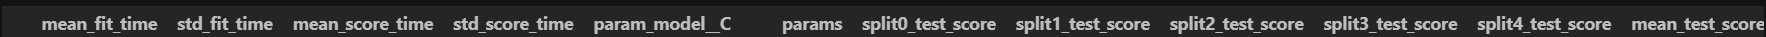

Daher wird der Frame angepasst, um einfach vergleichen zu können.

In [35]:
comparison = results[
    ["param_model__C", "mean_test_score", "std_test_score", "rank_test_score"]
].rename(columns={
    "param_model__C": "C",
    "mean_test_score": "F1_Mittelwert",
    "std_test_score": "F1_Streuung",
    "rank_test_score": "Rang",
})

comparison.sort_values("C").round(6)

,C,F1_Mittelwert,F1_Streuung,Rang
0,0.01,0.345596,0.027308,5
1,0.10,0.435381,0.022599,4
2,1.00,0.443399,0.017444,3
3,10.00,0.445954,0.014767,1
4,100.00,0.445954,0.014767,1


In der Tabelle sieht man die Mittelwert für **F1**.  \
Es ist zu erkenne, dass sich **F1** ändert, aber mit **C** = 10 oder 100 sich der Bestwert für **C** ergibt.  \
Somit war **C** des Basismodells (**C=1** als Standardwert) bereits gut gewählt.
In der Cross-Validation schneiden C=10 und C=100 etwas besser ab als C=1.  \
Auf den separaten Testdaten bringt das ausgewählte Modell keine Verbesserung des **F1-Scores.**

**C** ist nur eine Stellschraube.  \
Damit wurde nur die Regularisierung verändert.
Das Modell kann trotzdem zu einfach sein, um die Zusammenhänge gut abzubilden.

Mögliche nächste Schritte um Modell zu verbessern:
| Ansatz | Was verändert sich? |
|---|---|
| **Klassengewichtung** | Die seltenere Klasse erhält beim Training mehr Gewicht. |
| **Entscheidungsschwelle** | Wir verändern, ab welcher vorhergesagten Wahrscheinlichkeit eine Probe als sicher gilt. |
| **Anderes Modell** | Beispielsweise können Entscheidungsbäume oder Random Forests andere Zusammenhänge lernen. |
| **Bessere Merkmale und Daten** | Wir untersuchen fehlerhafte Werte, fehlende Informationen oder hilfreiche Kombinationen der Messwerte. |

Als erstes verändern wir die Klassengewichtung, heißt Proben mit ```is_safe``` haben mehr Bedeutung als unsichere Proben.  \
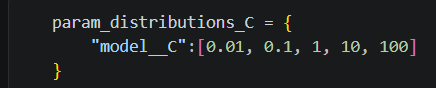  \
→ Standardmäßig ist ```C=1``` und ```class_weight=None```

Dazu wird ein neues Dictionary aufgesetzt mit beiden Hyperparametern geändert:

In [39]:
param_distributions_C_class_weight = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}

```n_iter``` muss nun 10 sein, da 5x2 Werte betrachtet werden müssen.

In [40]:
hyper_param_C_class_weight_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions_C_class_weight,
    n_iter=10,
    scoring="f1",
    cv=5,
    random_state=42
)

In [41]:
hyper_param_C_class_weight_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,

In [43]:
y_pred_tuned_C_class_weight = hyper_param_C_class_weight_search.predict(X_test)

In [48]:
print("Baseline:")
print(classification_report(y_test, y_pred, digits=5))

print("After Tuning C and class_weight:")
print(classification_report(y_test, y_pred_tuned_C_class_weight, digits=5))

print("Best Parameter for C and class_weight:", hyper_param_C_class_weight_search.best_params_)

Baseline:
              precision    recall  f1-score   support

       False    0.91953   0.98307   0.95024      1418
        True    0.71429   0.32967   0.45113       182

    accuracy                        0.90875      1600
   macro avg    0.81691   0.65637   0.70068      1600
weighted avg    0.89618   0.90875   0.89346      1600

After Tuning C and class_weight:
              precision    recall  f1-score   support

       False    0.95754   0.81100   0.87820      1418
        True    0.32832   0.71978   0.45095       182

    accuracy                        0.80063      1600
   macro avg    0.64293   0.76539   0.66457      1600
weighted avg    0.88596   0.80063   0.82960      1600

Best Parameter for C and class_weight: {'model__class_weight': 'balanced', 'model__C': 0.01}


Man sieht das ``Recall`` steigt, also mehr Proben die sicher sind als sicher vorhergesagt werden, dabei werden allerdings auch mehr unsichere Proben als sicher bewertet.  \
→ ````Precision```` fällt deutlich. Dadurch ist der **F1-Score** auch schlechter.

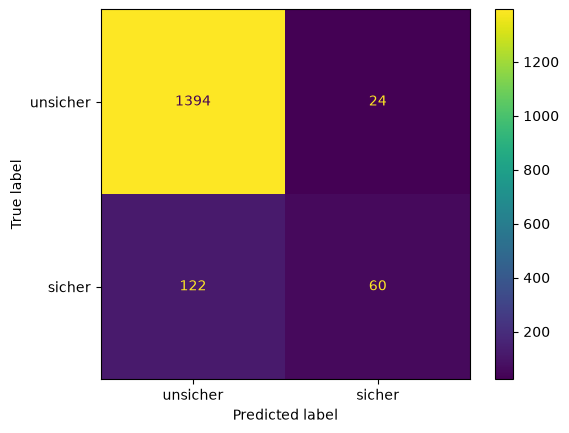

In [51]:
#Basismodell
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["unsicher","sicher"]
)

plt.show()

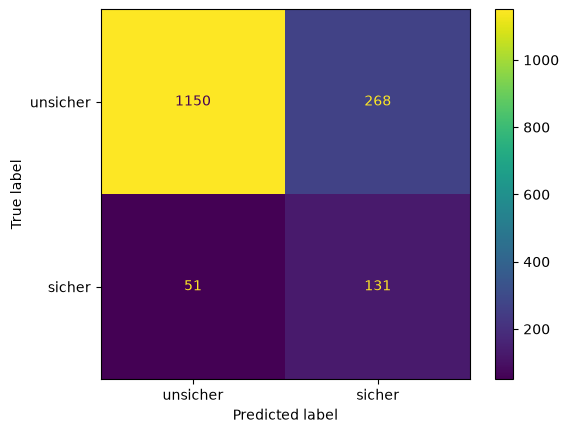

In [ ]:
#Getuntes Modell
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned_C_class_weight,
    display_labels=["unsicher","sicher"]
)

plt.show()

Die Entscheidungsschwelle ändern ist ein sinnvoller nächster Versuch.  \
Sie verändert, ab wann das Modell „sicher“ vorhersagt – die gelernten Zusammenhänge bleiben dabei gleich.  \
Die Schwelle liegt standardmäßig bei 0.5

| Änderung | Typische Auswirkung |
|---|---|
| **Schwelle erhöhen**, beispielsweise auf 0,7 | Weniger Proben werden als sicher eingestuft. Recall sinkt; Precision kann steigen. |
| **Schwelle senken**, beispielsweise auf 0,3 | Mehr Proben werden als sicher eingestuft. Recall steigt; Precision kann sinken. |

→ Beides nicht hilfreich, ein guten Modell zu erstellen

Nächster sinnvoller Schritt: Aktuelles Modell mit einem **Random Forest** vergleichen.

Ein **Random Forest** kombiniert viele Entscheidungsbäume.  \
Diese können unterschiedliche Wertebereiche und Kombinationen von Merkmalen berücksichtigen.

Auch **Gradient Boosting** wäre anschließend ein sinnvoller Kandidat.  \
Ob sie bei den Daten besser funktionieren, muss geprüft werden.